# RoadWatch AI

RoadWatch AI is a phone app that turns every drive into a pothole survey.
The driver mounts their phone on the dashboard and starts recording. While
they drive, the app watches the road, detects potholes, works out how big
each one is and where it is, shows them on a map, and prepares a report for
the road authorities.

## Table of Contents

- [1. About the model and data](#scrollTo=roadwatch-000)
- [2. Data exploration](#scrollTo=ERyd3vosiUCI)
- [3. Data Cleaning](#scrollTo=lWZr6NNoiIJ_)
- [4 Model training and results](#scrollTo=ePSREcT4wS6X)
- [5 What remains and future work](#scrollTo=4NK40ZgzwuEI)

## 1. About the model and data

### The Model

RoadWatchAI uses, a deep learning model made for detecting
objects in images and video. For every frame it returns three things: where
each pothole is (a box), what it is, and how confident the model is.
We use the small versions (**nano** and **small**) because they are fast
enough for a phone and train on free Google Colab GPUs. We train it with the
**Ultralytics** Python library.

We don't start from scratch. YOLO11 comes already trained on a large general
dataset, so it already knows how to see edges, shapes and objects. We then
train it further on pothole images so it learns what a pothole looks like.
This is called fine-tuning, and it needs far less data and time than
training from zero.

### The data
- **Dataset:** "Pothole Detection Dataset: YOLOv11 Optimized" by Muskan
  Verma on Kaggle, originally from Roboflow Universe. License: CC BY 4.0.
- **Size:** about 3,900 road images, resized to 640x640 pixels.
- **Labels:** each image comes with a text file listing a box around every
  pothole.
- **Augmentation:** Roboflow made three versions of each original image by
  randomly flipping it, so the training set contains flipped copies.
- **Splits:** the data comes already divided into three parts:
  - **train:** what the model learns from
  - **valid:** used while training to check progress and tune settings
  - **test:** kept aside and used once at the end for the final score

## 2. Data exploration

### Fetching the data

In [ ]:
!pip install -q kagglehub

import shutil
from pathlib import Path
import kagglehub

DATASET_DIR = Path("data/raw/muskanverma24-pothole-yolo11")

path = kagglehub.dataset_download("muskanverma24/pothole-detection-dataset-yolov11-optimized")
print("Downloaded to:", path)

shutil.copytree(path, DATASET_DIR, dirs_exist_ok=True)

100%|██████████| 215M/215M [00:01<00:00, 151MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/muskanverma24/pothole-detection-dataset-yolov11-optimized/versions/1


PosixPath('data/raw/muskanverma24-pothole-yolo11')

### Install packages

Installs the libraries this notebook needs when running in Google Colab. `ultralytics` is pinned to one exact version so everyone gets the same behavior, and `ImageHash` is used later to find near-duplicate images. On a local machine this step is skipped, so use your project environment instead.

In [ ]:
import sys, subprocess
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'ultralytics==8.4.189', 'pandas', 'matplotlib', 'Pillow', 'ImageHash'], check=True)
else:
    print('Local use: activate the project environment with pandas, matplotlib, Pillow and ImageHash.')


In [ ]:
from pathlib import Path
import sys, subprocess, os, json, csv, hashlib, zipfile, math, random, shutil
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import imagehash
from IPython.display import display, Image as NotebookImage

REPO_URL = 'https://github.com/i-ssa/SemProject_MLEngine.git'
REPO_REV = 'fec771dd5b55baacfb909dc28bd762e800e050d9'
IN_COLAB = Path('/content').is_dir()
if IN_COLAB:
    DRIVE_ROOT = Path('/content/drive/MyDrive')
    ROOT = Path('/content/RoadWatch_presentation_reference')
    if not ROOT.exists():
        subprocess.run(['git', 'clone', REPO_URL, str(ROOT)], check=True)
        subprocess.run(['git', '-C', str(ROOT), 'checkout', '--detach', REPO_REV], check=True)
    actual = subprocess.check_output(['git', '-C', str(ROOT), 'rev-parse', 'HEAD'], text=True).strip()
    assert actual == REPO_REV, 'Reference checkout differs; choose a new empty reference folder or inspect it first.'
    DATA_ROOT = Path('/content/roadwatch_cleaned')
    ARCHIVE = DRIVE_ROOT / 'roadwatch_cleaned_v3.zip'
    RUNS_DIR = DRIVE_ROOT / 'RoadWatch_cleaned_training'
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p/'data/1/train/images').is_dir()), None)
    assert ROOT is not None, 'Run locally from the cloned project root.'
    DATA_ROOT = ROOT / 'data/cleaned'
    ARCHIVE = Path.home() / 'Downloads/roadwatch_cleaned_v3.zip'
    RUNS_DIR = ROOT / 'runs'
RAW = ROOT / 'data/1'
WORK = Path('/content/roadwatch_notebook_work') if IN_COLAB else Path('/tmp/roadwatch_notebook_work')
WORK.mkdir(parents=True, exist_ok=True)
RUN_NAME = 'pothole_yolo11s_cleaned_v3'
BEST_WEIGHTS = RUNS_DIR / RUN_NAME / 'weights/best.pt' if IN_COLAB else ROOT/'models/best.pt'
SPLITS = ('train', 'valid', 'test')
EXPECTED = {'train': (3196,8141), 'valid': (375,1097), 'test': (369,873)}
EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.webp'}
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()
print('Reference files:', ROOT)
print('Cleaned data:', DATA_ROOT)
print('Checkpoint:', BEST_WEIGHTS)
print('Working outputs:', WORK)

# Drive is only needed to restore data or load the trained checkpoint.
DRIVE_READY = not IN_COLAB
if IN_COLAB:
    try:
        if not DRIVE_ROOT.is_dir():
            from google.colab import drive
            drive.mount('/content/drive')
        DRIVE_READY = DRIVE_ROOT.is_dir()
    except (ValueError, RuntimeError, OSError) as exc:
        print('Drive connection failed:', str(exc))
        print('You can still display saved results in section 4. For data or inference, reconnect Drive and rerun this cell.')


### Load and verify the cleaned dataset

Rebuilds the cleaned dataset archive (joining the transfer parts if needed), checks its checksum, and extracts it safely. Then it writes a `data.yaml` with this machine's paths and checks the image and box counts for each split against the expected values.

The notebook stops with an error if any check fails.

In [ ]:
# Assemble the transfer parts if needed, verify the archive, then extract safely.
DATASET_SHA = '31fff83565a63da76e32419825cd8b613f5aac322ed00df62470b53f9bf4785e'
if IN_COLAB:
    if not DRIVE_ROOT.is_dir():
        raise RuntimeError('Drive is not connected. Rerun the setup cell and approve Drive access before restoring the cleaned dataset.')
    if not ARCHIVE.exists():
        parts = [Path(str(ARCHIVE)+f'.part{i:03d}') for i in (1,2,3)]
        assert all(p.is_file() for p in parts), 'Put the complete ZIP or all three parts in My Drive.'
        assembled = WORK / 'roadwatch_cleaned_v3.zip'
        with assembled.open('wb') as out:
            for part in parts:
                with part.open('rb') as inp: shutil.copyfileobj(inp, out)
        ARCHIVE = assembled
    assert sha256(ARCHIVE) == DATASET_SHA, 'Dataset archive checksum differs.'
    # Reuse the exact archive; files are verified against the manifests later.
    with zipfile.ZipFile(ARCHIVE) as z:
        destination = DATA_ROOT.parent.resolve()
        for item in z.infolist():
            resolved = (destination/item.filename).resolve()
            assert resolved.is_relative_to(destination), 'Unsafe ZIP path'
            if item.filename.endswith('/'): continue
            assert item.filename.startswith('roadwatch_cleaned/'), 'Unexpected archive layout'
        z.extractall(destination)
assert DATA_ROOT.is_dir(), 'Cleaned-v3 folder is missing.'
# Generate a machine-specific YAML without changing the archive configuration.
DATA_YAML = WORK/'cleaned_v3_data.yaml'
DATA_YAML.write_text('path: '+DATA_ROOT.as_posix()+'\ntrain: train/images\nval: valid/images\ntest: test/images\nnc: 1\nnames:\n  0: pothole\n')
for split,(n_images,n_boxes) in EXPECTED.items():
    folder=DATA_ROOT/split
    images=[p for p in (folder/'images').iterdir() if p.suffix.lower() in EXTENSIONS]
    labels=list((folder/'labels').glob('*.txt'))
    assert len(images)==len(labels)==n_images
    assert {p.stem for p in images}=={p.stem for p in labels}
    count=sum(len([l for l in p.read_text().splitlines() if l.strip()]) for p in labels)
    assert count==n_boxes
    print(f'{split}: {len(images)} images, {count} boxes')
print('Cleaned-v3 inventory matches. Detailed validity checks follow in section 3.')


### Annotation table

Combines every image and its label file from train, valid and test into one CSV, with one row per image. Each pothole box gets its own set of columns (class, x, y, width, height), and images with fewer potholes leave the extra columns empty. The table is saved to the working folder and used for the analysis below.

In [ ]:
"""
This script combines the images and their corresponding label files
from the train, valid, and test folders into a single CSV file.

For each image, the CSV stores the image name and the dataset split.
The label files contain annotations in the format:
class_id, x_center, y_center, width, height.

Since an image can contain multiple potholes, each annotation is
stored in its own set of columns, such as:
class_id(1), x_center(1), y_center(1), width(1), height(1),
class_id(2), x_center(2), y_center(2), width(2), height(2), and so on.

The script first finds the highest number of annotations in any
label file and creates enough columns to accommodate all of them.
If an image has fewer annotations, the remaining columns are left empty.

The completed CSV file is saved in the data/ directory.
"""



import os
import pandas as pd

# Location of the dataset
data_dir = str(RAW)

# The dataset is divided into these three folders
splits = ["train", "valid", "test"]

# This is where the generated CSV will be saved
output_file = str(WORK / "pothole_annotations.csv")


# First, go through all the label files and find the image
# that contains the highest number of pothole annotations.
max_annotations = 0
total_images = 0
total_annotations = 0

for split in splits:
    images_dir = os.path.join(data_dir, split, "images")
    labels_dir = os.path.join(data_dir, split, "labels")

    image_files = [
        file for file in os.listdir(images_dir)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    total_images += len(image_files)

    for image_file in image_files:
        image_name = os.path.splitext(image_file)[0]
        label_file = os.path.join(labels_dir, image_name + ".txt")

        if not os.path.exists(label_file):
            continue

        with open(label_file, "r") as file:
            annotations = [
                line.strip()
                for line in file
                if line.strip()
            ]

        number_of_annotations = len(annotations)
        total_annotations += number_of_annotations

        if number_of_annotations > max_annotations:
            max_annotations = number_of_annotations


print(f"Total images: {total_images}")
print(f"Total annotations: {total_annotations}")
print(f"Maximum potholes in one image: {max_annotations}")


# Create the CSV columns based on the maximum number of
# potholes found in a single image.
columns = ["image_name", "split"]

for i in range(1, max_annotations + 1):
    columns.extend([
        f"class_id({i})",
        f"x_center({i})",
        f"y_center({i})",
        f"width({i})",
        f"height({i})"
    ])


# Read each image and its corresponding label file.
# All annotations belonging to an image will be stored
# in the same row.
rows = []

for split in splits:
    images_dir = os.path.join(data_dir, split, "images")
    labels_dir = os.path.join(data_dir, split, "labels")

    image_files = [
        file for file in os.listdir(images_dir)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    print(f"Processing {split}: {len(image_files)} images")

    for image_file in image_files:
        image_name = os.path.splitext(image_file)[0]
        label_file = os.path.join(labels_dir, image_name + ".txt")

        # Store the image name and the dataset split
        row = {
            "image_name": image_file,
            "split": split
        }

        if os.path.exists(label_file):
            with open(label_file, "r") as file:
                annotations = [
                    line.strip()
                    for line in file
                    if line.strip()
                ]

            # Each line in the label file represents one pothole
            for i, annotation in enumerate(annotations, start=1):
                values = annotation.split()

                # YOLO annotation format:
                # class_id, x_center, y_center, width, height
                if len(values) != 5:
                    print(f"Invalid annotation in: {label_file}")
                    continue

                class_id, x_center, y_center, width, height = values

                row[f"class_id({i})"] = int(class_id)
                row[f"x_center({i})"] = float(x_center)
                row[f"y_center({i})"] = float(y_center)
                row[f"width({i})"] = float(width)
                row[f"height({i})"] = float(height)

        rows.append(row)


# Convert the collected rows into a DataFrame.
# Images with fewer potholes will have empty values
# in the columns for the missing annotations.
df = pd.DataFrame(rows, columns=columns)


# Save the completed dataset as a CSV file.
df.to_csv(output_file, index=False)


print(f"\nCSV saved to: {output_file}")
print(f"Rows: {len(df)}")
print(f"Columns: {len(df.columns)}")

print("\nImages by split:")
print(df["split"].value_counts())

display(df.head())


Total images: 3940
Total annotations: 10111
Maximum potholes in one image: 21
Processing train: 3345 images
Processing valid: 397 images
Processing test: 198 images

CSV saved to: /tmp/roadwatch_notebook_work/pothole_annotations.csv
Rows: 3940
Columns: 107

Images by split:
split
train    3345
valid     397
test      198
Name: count, dtype: int64


,image_name,split,class_id(1),x_center(1),y_center(1),width(1),height(1),class_id(2),x_center(2),y_center(2),width(2),height(2),class_id(3),x_center(3),y_center(3),width(3),height(3),class_id(4),x_center(4),y_center(4),width(4),height(4),class_id(5),x_center(5),y_center(5),width(5),height(5),class_id(6),x_center(6),y_center(6),width(6),height(6),class_id(7),x_center(7),y_center(7),width(7),height(7),class_id(8),x_center(8),y_center(8),width(8),height(8),class_id(9),x_center(9),y_center(9),width(9),height(9),class_id(10),x_center(10),y_center(10),width(10),height(10),class_id(11),x_center(11),y_center(11),width(11),height(11),class_id(12),x_center(12),y_center(12),width(12),height(12),class_id(13),x_center(13),y_center(13),width(13),height(13),class_id(14),x_center(14),y_center(14),width(14),height(14),class_id(15),x_center(15),y_center(15),width(15),height(15),class_id(16),x_center(16),y_center(16),width(16),height(16),class_id(17),x_center(17),y_center(17),width(17),height(17),class_id(18),x_center(18),y_center(18),width(18),height(18),class_id(19),x_center(19),y_center(19),width(19),height(19),class_id(20),x_center(20),y_center(20),width(20),height(20),class_id(21),x_center(21),y_center(21),width(21),height(21)
0,01_jpg.rf.311d897b199b9edde57b99bc4b606074.jpg,train,0,0.492969,0.306250,0.451562,0.223438,0.0,0.549219,0.623437,0.430469,0.317188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01_jpg.rf.bf7e43382a861a8c57127bca8c177a2d.jpg,train,0,0.492969,0.306250,0.451562,0.223438,0.0,0.549219,0.623437,0.430469,0.317188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,02_jpg.rf.2788bebeb55f808442e3a7e04f8fcea8.jpg,train,0,0.482031,0.551562,0.964063,0.670312,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,02_jpg.rf.bf08db3e12adb8f7cff300bac0297ab0.jpg,train,0,0.517969,0.551562,0.964063,0.670312,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,03_jpg.rf.33e1ef5733f131973cfa5aeef0d0d625.jpg,train,0,0.514062,0.628906,0.829688,0.435156,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Check the table

Confirms the annotation table has one row per image (3,940) and 107 columns, which means the busiest image has 21 potholes. The notebook stops here if the shape is different.

One row represents an image. There is space for up to 21 boxes, each with five fields, plus the image name and split: 2 + (21 × 5) = 107 columns. This is the shape of our derived CSV, not 107 model input features.


In [ ]:
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
assert df.shape == (3940,107)


Rows: 3940
Columns: 107


### Check the column types

Shows how many columns are text and how many are numbers, plus the types of the first 12 columns.

In [ ]:
display(df.dtypes.astype(str).value_counts().to_frame('Number of columns'))
display(df.dtypes.head(12).to_frame('Example column types'))


,Number of columns
float64,104
str,2
int64,1


,Example column types
image_name,str
split,str
class_id(1),int64
x_center(1),float64
y_center(1),float64
width(1),float64
height(1),float64
class_id(2),float64
x_center(2),float64
y_center(2),float64


### Check for blanks

Counts the empty entries in the first 12 columns and the last 5. Image name and split should never be blank.

Blank box slots are normal. An image with one pothole has values for the first box and blanks for the unused second through twenty-first boxes, and blanks in the first slot mark images with no potholes at all. These blanks are padding, not missing potholes, so we do not fill them with zeros.

This check alone cannot prove that every visible pothole has been annotated.

In [ ]:
missing = df.isna().sum()
# Show early boxes and the final box slots without printing all 107 columns.
display(pd.concat([missing.head(12), missing.tail(5)]).to_frame('Blank entries'))


,Blank entries
image_name,0
split,0
class_id(1),0
x_center(1),0
y_center(1),0
width(1),0
height(1),0
class_id(2),1767
x_center(2),1767
y_center(2),1767


### Catalogue the original dataset

Makes a list of every image with its labels, size and original photo name. Then it loads the file that says which split (train, valid or test) each image belongs to, and checks it covers exactly the same 3,940 images.

In [ ]:
records=[]
for split in SPLITS:
    for path in sorted((RAW/split/'images').iterdir()):
        if path.suffix.lower() not in EXTENSIONS: continue
        label=RAW/split/'labels'/(path.stem+'.txt')
        assert label.is_file(), f'Missing label: {path.name}'
        lines=[l.split() for l in label.read_text().splitlines() if l.strip()]
        assert all(len(l)==5 for l in lines), 'Invalid label format'
        boxes=[tuple(map(float,l[1:])) for l in lines]
        with Image.open(path) as im: size=im.size
        records.append(dict(image=path.name,source=path.stem.split('.rf.')[0],
                            original_split=split,path=path,label=label,boxes=boxes,size=size))
by_name={r['image']:r for r in records}
assert len(by_name)==len(records)==3940
with (ROOT/'data/split_manifest_v3.csv').open() as f:
    final_manifest=list(csv.DictReader(f))
assert len(final_manifest)==len(records)
assert {r['image'] for r in final_manifest}==set(by_name)
assignment={r['image']:r['new_split'] for r in final_manifest}
print('Images:',len(records),'| annotated potholes:',sum(len(r['boxes']) for r in records))


Images: 3940 | annotated potholes: 10111


### Potholes per image

Counts how many potholes are annotated in each image and shows the result as a bar chart. This tells us whether most images contain a single pothole or several, how crowded the busiest image is, and whether any images have no potholes. Each original photo appears three times in the dataset because of the flips, so the bars count images, not distinct photos.

Range: 1 to 21 | one-pothole images: 1767


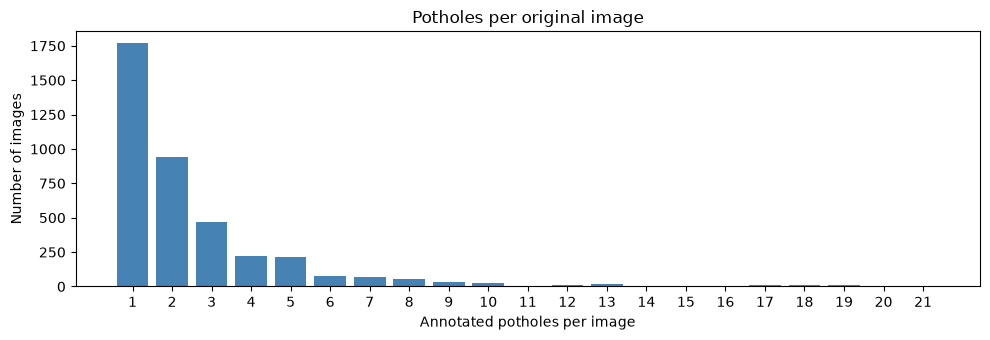

In [ ]:
counts=Counter(len(r['boxes']) for r in records)
fig,ax=plt.subplots(figsize=(10,3.5))
ax.bar(sorted(counts),[counts[k] for k in sorted(counts)],color='steelblue')
ax.set(title='Potholes per original image',xlabel='Annotated potholes per image',ylabel='Number of images')
ax.set_xticks(range(1,max(counts)+1));plt.tight_layout();plt.show()
print('Range:',min(counts),'to',max(counts),'| one-pothole images:',counts[1])


## 3. Data Cleaning

### Do similar filenames mean the same photo?

Counts the distinct source names behind the image files, then shows three images that share one source name. If they are flipped copies of the same photo, the source name can be used to keep all copies in the same split. The titles show which original split each copy came from.

Image files: 3940 | filename source groups: 834


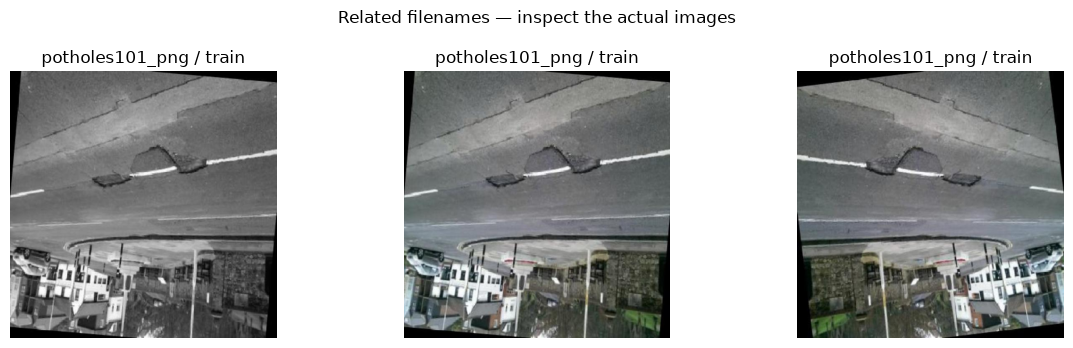

In [ ]:
source_counts=Counter(r['source'] for r in records)
print('Image files:',len(records),'| filename source groups:',len(source_counts))
group=next(g for g,n in source_counts.most_common() if n>=3)
examples=[r for r in records if r['source']==group][:3]
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,r in zip(axes,examples):
    with Image.open(r['path']) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(r['source']+' / '+r['original_split']);ax.axis('off')
fig.suptitle('Related filenames — inspect the actual images');plt.tight_layout();plt.show()


### Did the cleaning remove the split leakage?

Counts how many source photos have copies in more than one split (train, valid or test), first in the original split and then in the cleaned version. Copies of the same photo in different splits let the model see its test images during training and make the scores look better than they really are. The cleaned split should show zero.


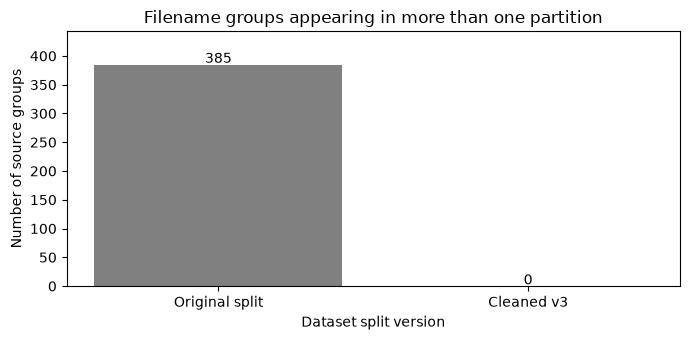

In [ ]:
def leaking_groups(rows,key,split_key):
    groups=defaultdict(set)
    for r in rows: groups[r[key]].add(r[split_key])
    return {g:s for g,s in groups.items() if len(s)>1}
old_overlap=len(leaking_groups(records,'source','original_split'))
new_overlap=len(leaking_groups(final_manifest,'source','new_split'))
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(['Original split','Cleaned v3'],[old_overlap,new_overlap],color=['gray','steelblue'])
ax.set(title='Filename groups appearing in more than one partition',ylabel='Number of source groups',xlabel='Dataset split version')
for i,v in enumerate([old_overlap,new_overlap]):ax.text(i,v+3,str(v),ha='center')
ax.set_ylim(0,max(old_overlap,1)*1.15);plt.tight_layout();plt.show()


### Images with and without annotations

Counts how many images have at least one pothole annotated and how many have an empty label file. Empty label files act as examples of roads without potholes, which help the model avoid false alarms, though an empty file could also mean a pothole was missed by the annotators.

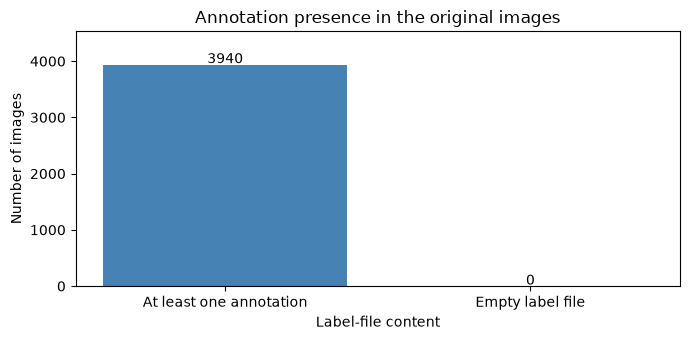

In [ ]:
empty=sum(not r['boxes'] for r in records)
fig,ax=plt.subplots(figsize=(7,3.5))
values=[len(records)-empty,empty]
ax.bar(['At least one annotation','Empty label file'],values,color=['steelblue','gray'])
for i,v in enumerate(values):ax.text(i,v+25,str(v),ha='center')
ax.set(title='Annotation presence in the original images',ylabel='Number of images',xlabel='Label-file content',ylim=(0,len(records)*1.15))
plt.tight_layout();plt.show()


### How big are the potholes?

Measures each annotated box as a percentage of the image area and plots the distribution, with the median printed below. This shows whether potholes are mostly small or large in the frame, which matters for how well the model will detect them and for choosing the small, medium and large cutoffs. Sizes are relative to the image, not real-world measurements.

Median box area: 2.832% of image area


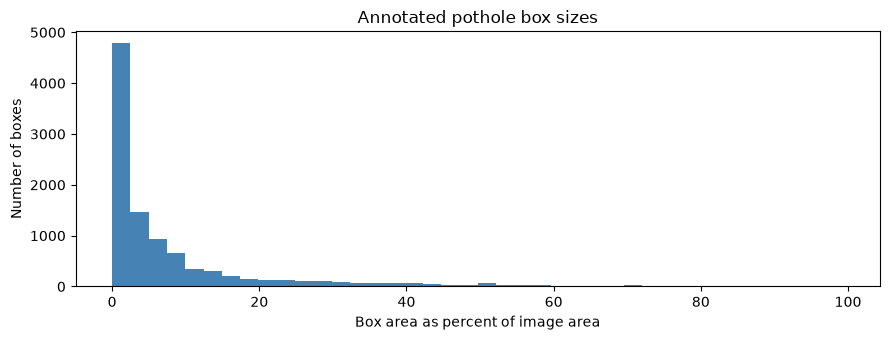

In [ ]:
areas=np.array([w*h for r in records for x,y,w,h in r['boxes']])
fig,ax=plt.subplots(figsize=(9,3.5))
ax.hist(areas*100,bins=40,color='steelblue')
ax.set(title='Annotated pothole box sizes',xlabel='Box area as percent of image area',ylabel='Number of boxes')
plt.tight_layout();plt.show()
print(f'Median box area: {np.median(areas)*100:.3f}% of image area')


### Pair every image with its label file

For each split, lists the images and label files and checks they match one to one: no image without a label, no label without an image, and no two images that share a name. Then it records each image with its split and source name (the original photo it came from). The notebook stops if any pairing problem is found.

In [ ]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
records = []
pairing_errors = []
for split in SPLITS:
    images = sorted(p for p in (RAW / split / 'images').iterdir()
                    if p.suffix.lower() in EXTENSIONS)
    labels = {p.stem: p for p in (RAW / split / 'labels').glob('*.txt')}
    stems = Counter(p.stem for p in images)
    pairing_errors += [(split, 'ambiguous image stem', s) for s,n in stems.items() if n > 1]
    pairing_errors += [(split, 'orphan label', s) for s in labels if s not in stems]
    for p in images:
        label = labels.get(p.stem)
        if label is None:
            pairing_errors.append((split, 'missing label', p.name))
        records.append(dict(image=p.name, original_split=split,
                            source=p.stem.split('.rf.')[0], path=p, label=label))
    print(split, len(images), 'images,', len(labels), 'labels')
assert not pairing_errors, pairing_errors[:20]
assert len({r['image'] for r in records}) == len(records), 'Ambiguous manifest image names'
by_name = {r['image']: r for r in records}
print('Images:', len(records), '| source groups:', len({r['source'] for r in records}))


train 3345 images, 3345 labels
valid 397 images, 397 labels
test 198 images, 198 labels
Images: 3940 | source groups: 834


In [ ]:
def read_boxes(path):
    boxes = []
    for line_number, line in enumerate(path.read_text().splitlines(), 1):
        if not line.strip():
            continue
        values = line.split()
        assert len(values) == 5, f'{path.name}:{line_number}: expected 5 fields'
        cls, x, y, w, h = map(float, values)
        assert all(math.isfinite(v) for v in (cls,x,y,w,h)), 'Nonfinite value'
        assert cls == 0, 'Expected pothole class 0'
        assert 0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1
        eps = 1e-6
        assert x-w/2 >= -eps and y-h/2 >= -eps
        assert x+w/2 <= 1+eps and y+h/2 <= 1+eps
        boxes.append((x,y,w,h))
    return boxes

errors = []
for r in records:
    try:
        with Image.open(r['path']) as im:
            im.verify()
        with Image.open(r['path']) as im:
            im.load()
            r['size'] = im.size
        r['boxes'] = read_boxes(r['label'])
    except Exception as exc:
        errors.append((r['image'], str(exc)))
print('Invalid images/labels:', len(errors))
assert not errors, errors[:20]
print('Boxes:', sum(len(r['boxes']) for r in records))
print('Empty labels:', sum(not r['boxes'] for r in records))


Invalid images/labels: 0
Boxes: 10111
Empty labels: 0


### Look at some labelled images
Draws the label boxes on three randomly chosen images so we can check by eye that they sit on potholes. The selection uses a fixed random seed, so the same three images appear every time. The earlier checks cannot tell whether a box is around the right object, so this step is done by looking. Three images is only a small sample.

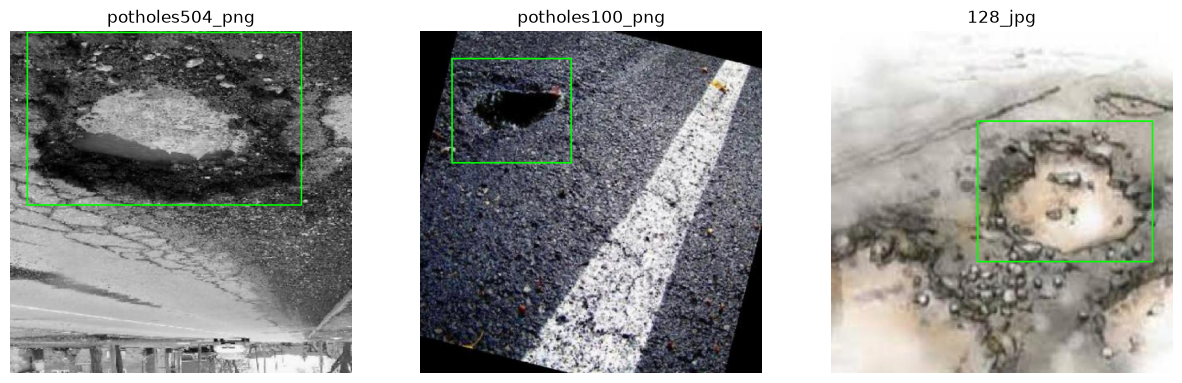

In [ ]:
# We overlay a few labels to inspect the boxes against the images.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, r in zip(axes, random.Random(42).sample(records, 3)):
    with Image.open(r['path']) as im:
        im = im.convert('RGB')
    draw = ImageDraw.Draw(im)
    W,H = im.size
    for x,y,w,h in r['boxes']:
        draw.rectangle(((x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H), outline='lime', width=3)
    ax.imshow(im); ax.set_title(r['source']); ax.axis('off')
plt.show()


### Look for duplicates
Fingerprints every image with SHA-256 to find files that are exactly the same, then counts how many photos have copies in more than one split. This is checked two ways: by the original-photo name in the file name, and by the exact file fingerprint. Copies of one photo in both train and test make the scores look better than they really are. These counts describe the original dataset, before cleaning. Exact fingerprints cannot find copies that were flipped or resized, which is why the filename check is included.

In [ ]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
exact = defaultdict(list)
for r in records:
    r['sha256'] = sha256(r['path'])
    exact[r['sha256']].append(r)
duplicate_sets = [v for v in exact.values() if len(v) > 1]
print('Exact duplicate sets:', len(duplicate_sets))
print('Extra copies:', sum(len(v)-1 for v in duplicate_sets))
def leaking_groups(rows, key, split_key):
    groups = defaultdict(set)
    for r in rows:
        groups[r[key]].add(r[split_key])
    return {k: v for k,v in groups.items() if len(v) > 1}
print('Original source groups spanning splits:', len(leaking_groups(records, 'source', 'original_split')))
print('Original exact hashes spanning splits:', len(leaking_groups(records, 'sha256', 'original_split')))


Exact duplicate sets: 0
Extra copies: 0
Original source groups spanning splits: 385
Original exact hashes spanning splits: 0


### Divide the photos fairly
Shows how the photos can be divided into train, valid and test so that copies of the same photo always stay together. Then it opens the two saved division lists (v2 and v3) and checks they are complete and fair. The notebook stops if either one has a problem.

In [ ]:
groups = sorted({r['source'] for r in records})
random.Random(42).shuffle(groups)
a, b = int(.8*len(groups)), int(.9*len(groups))
proposal = {g: ('train' if i < a else 'valid' if i < b else 'test')
            for i,g in enumerate(groups)}
print('Proposal images:', Counter(proposal[r['source']] for r in records))

def load_manifest(name):
    with (ROOT / 'data' / name).open(newline='') as f:
        rows = list(csv.DictReader(f))
    assert len(rows) == len(records)
    assert len({r['image'] for r in rows}) == len(rows)
    assert {r['image'] for r in rows} == set(by_name)
    for r in rows:
        raw = by_name[r['image']]
        assert r['source'] == raw['source']
        assert r['original_split'] == raw['original_split']
        assert int(r['annotations']) == len(raw['boxes'])
        assert r['new_split'] in SPLITS
    assert not leaking_groups(rows, 'source', 'new_split')
    return rows
v2 = load_manifest('split_manifest_v2.csv')
v3 = load_manifest('split_manifest_v3.csv')
print('Recorded v2 images:', Counter(r['new_split'] for r in v2))


Proposal images: Counter({'train': 3162, 'valid': 402, 'test': 376})
Recorded v2 images: Counter({'train': 3180, 'test': 385, 'valid': 375})


### Look for near-duplicate images across splits
Gives every image a short "look fingerprint" and compares all pairs. Two images in different splits whose fingerprints are almost the same are flagged, because they look like the same scene even if their file names differ. This runs on the v2 split. Flipped copies are not found this way, since a mirrored image has a different fingerprint, so those are handled by the filename check above.

In [ ]:
for r in records:
    with Image.open(r['path']) as im:
        r['phash'] = int(str(imagehash.phash(im, hash_size=8)), 16)

def cross_split_pairs(assignments):
    # About 7.8 million cheap integer comparisons for this dataset.
    pairs = []
    for i, left in enumerate(records):
        for right in records[i+1:]:
            if assignments[left['image']] == assignments[right['image']]:
                continue
            distance = (left['phash'] ^ right['phash']).bit_count()
            if distance <= 5:
                pairs.append((left['image'], right['image'], distance))
    return pairs
v2_assignment = {r['image']: r['new_split'] for r in v2}
flagged = cross_split_pairs(v2_assignment)
print('v2 cross-split pHash pairs:', len(flagged))
for pair in flagged:
    print(pair)


v2 cross-split pHash pairs: 8
('10_jpg.rf.27be1fcbf1edc25b626cfbf193263641.jpg', 'potholes504_png.rf.4633b38088985f578083ee44d4a414f9.jpg', 2)
('10_jpg.rf.8d9f5bea5bf29dbe49a633bb9d6ab154.jpg', 'potholes504_png.rf.5ad6aaa6cdb4ae810732b13b9dd9900b.jpg', 2)
('10_jpg.rf.8d9f5bea5bf29dbe49a633bb9d6ab154.jpg', 'potholes504_png.rf.a975845d7e750a3732c9ea9da3a74757.jpg', 2)
('18_jpg.rf.0b529fb857198125af8e3ec396cae79e.jpg', 'potholes19_png.rf.70cb59c1e547d6f79ec85049fd20cac3.jpg', 2)
('18_jpg.rf.2f53e5de78f37bc2da064ba97891c9dc.jpg', 'potholes19_png.rf.c9c4670b52e1bf1bb36567c6cd481c98.jpg', 2)
('355_jpg.rf.5b5ce9ea0e882009f84d2cae3df26c33.jpg', 'potholes263_png.rf.79dd72dfafa60b2b022d36057891cea9.jpg', 4)
('55_jpg.rf.6cb9cdacad845bbc83375ae2101adf03.jpg', 'potholes641_png.rf.4483312a14ad8c92748057ea5c2954f9.jpg', 4)
('21_jpg.rf.9e6ffad2a228077cb840ae800ac0e2af.jpg', 'potholes618_png.rf.238a9426c3e5e6d1135e47792ce03792.jpg', 0)


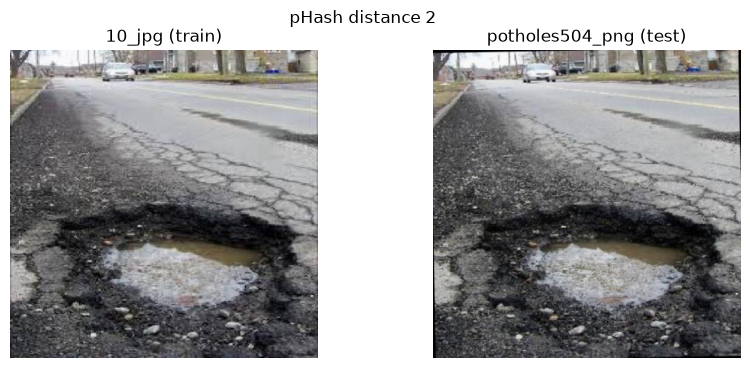

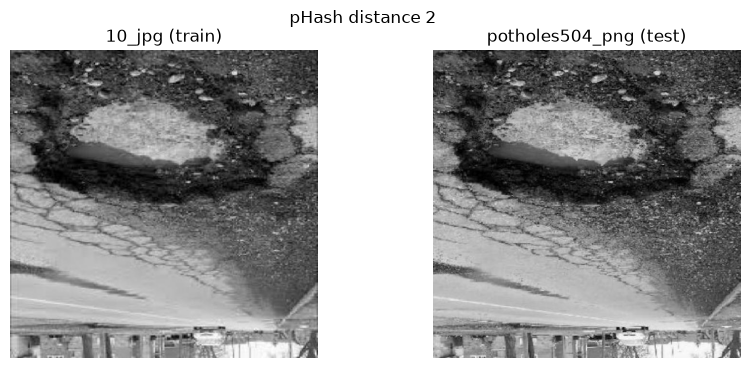

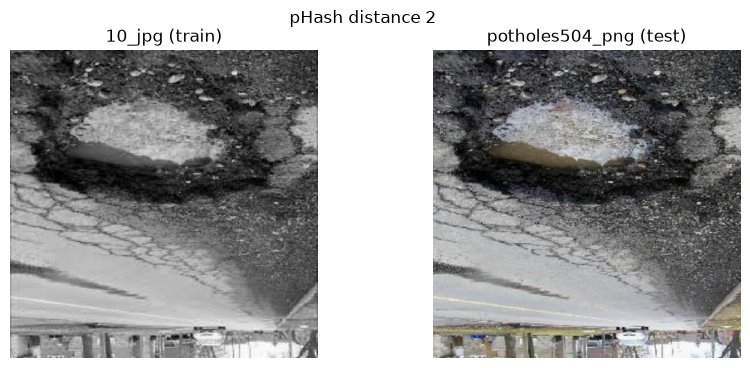

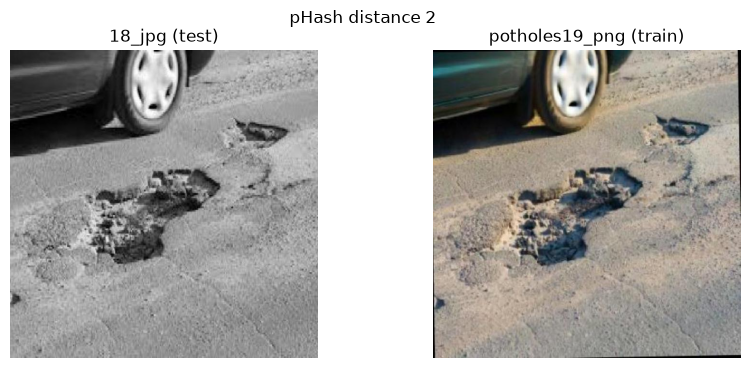

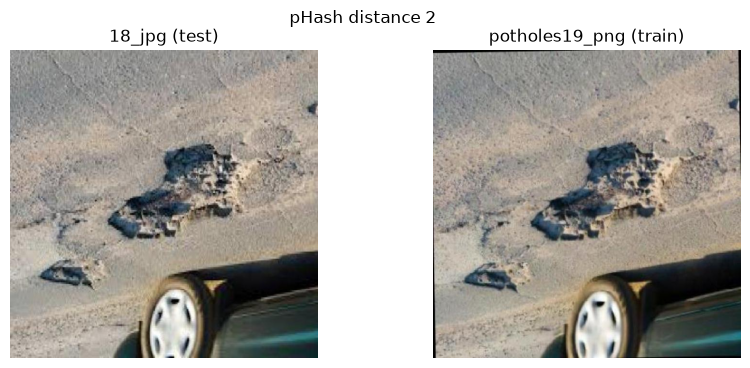

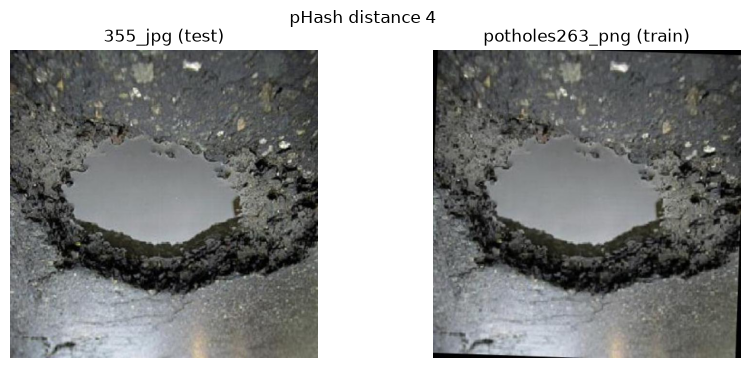

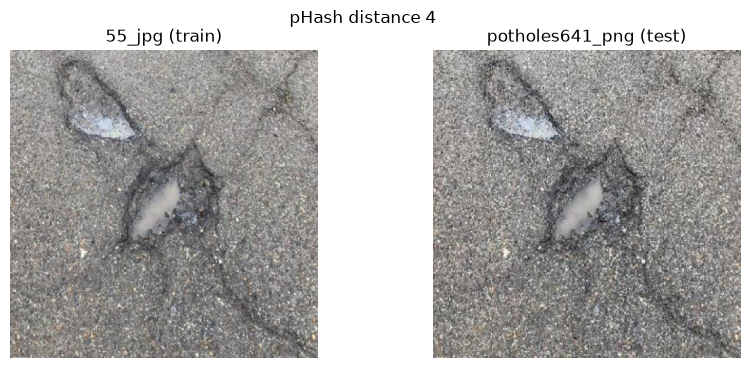

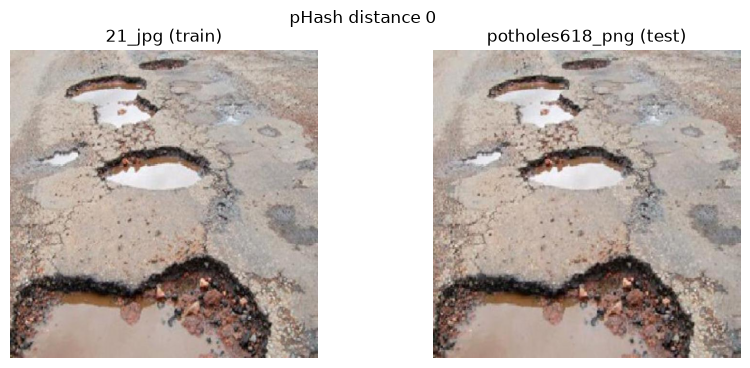

In [ ]:
# display the flagged pairs for visual review before replaying the recorded decisions.
for left, right, distance in flagged:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name in zip(axes, (left, right)):
        r = by_name[name]
        with Image.open(r['path']) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f"{r['source']} ({v2_assignment[name]})"); ax.axis('off')
    fig.suptitle(f'pHash distance {distance}')
    plt.show()


### Apply the fix and confirm the final split
Our review of the look-alike pairs found five photo groups (16 images) in the test set that resembled training images. We move them from test to train, which turns split v2 into the final split v3, and check that the result matches the saved v3 file exactly. Then we confirm the split is clean: no photo group appears in more than one split, no identical images are separated, no look-alike pairs remain across splits, and the image and box counts for train, valid and test match the expected values. The notebook stops if any check fails.

In [ ]:
MOVED_GROUPS = {'18_jpg', '355_jpg', 'potholes504_png', 'potholes618_png', 'potholes641_png'}
assert len(flagged) == 8, 'Review changed inputs before replaying historical decisions'
final = []
for row in v2:
    row = dict(row)
    if row['source'] in MOVED_GROUPS:
        assert row['new_split'] == 'test'
        row['new_split'] = 'train'
    final.append(row)
assert sum(r['source'] in MOVED_GROUPS for r in final) == 16
assert {r['image']: r for r in final} == {r['image']: r for r in v3}
assignment = {r['image']: r['new_split'] for r in final}
assert not leaking_groups(final, 'source', 'new_split')
assert all(len({assignment[r['image']] for r in group}) == 1 for group in duplicate_sets)
final_pairs = cross_split_pairs(assignment)
assert not final_pairs, final_pairs[:10]
assert len(records) == 3940 and len(groups) == 834
assert sum(len(r['boxes']) for r in records) == 10111
EXPECTED = {'train': (3196, 8141), 'valid': (375, 1097), 'test': (369, 873)}
for split in SPLITS:
    subset = [r for r in final if r['new_split'] == split]
    actual = (len(subset), sum(int(r['annotations']) for r in subset))
    assert actual == EXPECTED[split], (split, actual)
    print(split, actual[0], 'images;', actual[1], 'boxes')
print('Source leakage: 0; cross-split pHash matches <=5: 0')


train 3196 images; 8141 boxes
valid 375 images; 1097 boxes
test 369 images; 873 boxes
Source leakage: 0; cross-split pHash matches <=5: 0


### Check the cleaned dataset folder
Opens the cleaned dataset folder and confirms it matches the final split exactly. Each split must contain exactly the right images and label files, every file must be identical to the original (checked with file fingerprints), every image must open, every label must be valid, and the image and box counts must match the expected values. The notebook stops if anything differs.

In [ ]:
def validate_copy(folder):
    for split in SPLITS:
        rows = [r for r in final if r['new_split'] == split]
        expected_images = {r['image'] for r in rows}
        expected_labels = {by_name[r['image']]['label'].name for r in rows}
        assert {p.name for p in (folder/split/'images').iterdir() if p.is_file()} == expected_images
        assert {p.name for p in (folder/split/'labels').iterdir() if p.is_file()} == expected_labels
        count = 0
        for r in rows:
            raw = by_name[r['image']]
            image = folder/split/'images'/r['image']
            label = folder/split/'labels'/raw['label'].name
            assert sha256(image) == raw['sha256']
            assert sha256(label) == sha256(raw['label'])
            with Image.open(image) as im:
                im.load()
            count += len(read_boxes(label))
        assert (len(rows), count) == EXPECTED[split]
        print(folder.name, split, len(rows), 'images,', count, 'boxes: passed')

validate_copy(DATA_ROOT)
print('Cleaned-v3 file checks passed.')


cleaned train 3196 images, 8141 boxes: passed
cleaned valid 375 images, 1097 boxes: passed
cleaned test 369 images, 873 boxes: passed
Cleaned-v3 file checks passed.


In [ ]:
comparison=[]
for split in SPLITS:
    original=[r for r in records if r['original_split']==split]
    final_rows=[r for r in final if r['new_split']==split]
    comparison.append({'Partition':split,'Original images':len(original),
                       'Final images':len(final_rows),'Final boxes':sum(int(r['annotations']) for r in final_rows)})
display(pd.DataFrame(comparison))
print('Total retained images:',len(records),'— the split changed, the image total did not.')


Total retained images: 3940 — the split changed, the image total did not.


,Partition,Original images,Final images,Final boxes
0,train,3345,3196,8141
1,valid,397,375,1097
2,test,198,369,873


## 4. Model training and results

Run the setup immediately below before the other cells in this section. Saved-result mode is the default; no retraining is needed.


### The model
We use YOLO11s, the small version of YOLO11. It starts from pretrained `yolo11s.pt` and is fine-tuned on our pothole images. Training images teach the model, validation images help choose the checkpoint, and test images assess the chosen model.

### Run section 4 on its own
Run the next setup cell first, even after a fresh runtime restart. It defines the paths and loads the libraries needed for the saved curves, scores and examples. **Those displays do not need Drive, the dataset, a GPU or retraining.** They read the recovered experiment records from the public repository.

To make new predictions, enable model loading in the following cell. That step needs access to `best.pt`. Restoring the dataset is only necessary for new evaluation or training.


In [ ]:
from pathlib import Path
import subprocess, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

REPO_URL = 'https://github.com/i-ssa/SemProject_MLEngine.git'
REPO_REV = 'fec771dd5b55baacfb909dc28bd762e800e050d9'
IN_COLAB = Path('/content').is_dir()
# Optional local override; normally leave this as None.
REFERENCE_ROOT_OVERRIDE = None
if REFERENCE_ROOT_OVERRIDE is not None:
    ROOT = Path(REFERENCE_ROOT_OVERRIDE).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    previous_root = globals().get('ROOT')
    if previous_root is not None:
        candidates.insert(0, Path(previous_root))
    ROOT = next((p for p in candidates if (p/'reports/original_cleaned_v3/training/results.csv').is_file()), None)
    if ROOT is None and IN_COLAB:
        ROOT = Path('/content/RoadWatch_presentation_reference')
        if not ROOT.exists():
            subprocess.run(['git','clone',REPO_URL,str(ROOT)],check=True)
            subprocess.run(['git','-C',str(ROOT),'checkout','--detach',REPO_REV],check=True)
        revision = subprocess.check_output(['git','-C',str(ROOT),'rev-parse','HEAD'],text=True).strip()
        if revision != REPO_REV:
            raise RuntimeError('The reference folder has a different revision. Inspect it or set REFERENCE_ROOT_OVERRIDE to a verified project checkout.')
if ROOT is None:
    raise RuntimeError('Open this notebook from the project repository or set REFERENCE_ROOT_OVERRIDE above.')
required = ['reports/original_cleaned_v3/training/results.csv',
            'reports/verification_2026-10-27/evaluation_metrics.json',
            'reports/original_cleaned_v3/test_evaluation/val_batch0_labels.jpg',
            'reports/original_cleaned_v3/test_evaluation/val_batch0_pred.jpg']
missing = [name for name in required if not (ROOT/name).is_file()]
if missing:
    raise FileNotFoundError('Missing saved evidence in this checkout: '+', '.join(missing))
DRIVE_ROOT = Path('/content/drive/MyDrive') if IN_COLAB else Path.home()
RUNS_DIR = DRIVE_ROOT/'RoadWatch_cleaned_training' if IN_COLAB else ROOT/'runs'
RUN_NAME = 'pothole_yolo11s_cleaned_v3'
BEST_WEIGHTS = RUNS_DIR/RUN_NAME/'weights/best.pt' if IN_COLAB else ROOT/'models/best.pt'
DATA_ROOT = Path('/content/roadwatch_cleaned') if IN_COLAB else ROOT/'data/cleaned'
WORK = Path('/content/roadwatch_notebook_work') if IN_COLAB else Path('/tmp/roadwatch_notebook_work')
WORK.mkdir(parents=True, exist_ok=True)
DATA_YAML = WORK/'cleaned_v3_data.yaml'
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): digest.update(block)
    return digest.hexdigest()
best_model = None
HAS_GPU = False
DEVICE = 'cpu'
print('Section 4 ready. Saved evidence:', ROOT/'reports/original_cleaned_v3')
print('No Drive connection or training is needed to display the saved results.')


Section 4 ready. Saved evidence: /home/issa/3.2/AI/SemProject_MLEngine/reports/original_cleaned_v3
No Drive connection or training is needed to display the saved results.


In [ ]:
# Leave False to present saved results without a Drive connection.
# Set True only when you want to load best.pt for inference or a new evaluation.
LOAD_TRAINED_MODEL = False
CHECKPOINT_SHA = '9dad6abd86b08e02d76a02f5e0190ddf373b39de9b8487646f01a541e8810291'
best_model = None
if LOAD_TRAINED_MODEL:
    if IN_COLAB and not DRIVE_ROOT.is_dir():
        from google.colab import drive
        try:
            drive.mount('/content/drive')
        except (ValueError, RuntimeError, OSError) as exc:
            raise RuntimeError('Drive could not connect. Reconnect the runtime and approve Drive access, then rerun this cell. Saved-result displays do not need Drive.') from exc
    if not BEST_WEIGHTS.is_file():
        raise FileNotFoundError(f'Trained checkpoint missing: {BEST_WEIGHTS}. Copy the cleaned-v3 best.pt here; do not retrain to replace it.')
    if sha256(BEST_WEIGHTS) != CHECKPOINT_SHA:
        raise ValueError('Checkpoint checksum differs from the recorded cleaned-v3 experiment.')
    import sys, importlib.util
    if importlib.util.find_spec('ultralytics') is None:
        subprocess.run([sys.executable,'-m','pip','install','-q','ultralytics==8.4.189'],check=True)
    import torch, ultralytics
    if ultralytics.__version__ != '8.4.189':
        raise RuntimeError('Use the package-install cell to install Ultralytics 8.4.189, restart the runtime if requested, and rerun section 4 setup.')
    from ultralytics import YOLO
    HAS_GPU = torch.cuda.is_available()
    DEVICE = 0 if HAS_GPU else 'cpu'
    best_model = YOLO(str(BEST_WEIGHTS))
    print('Verified and loaded the saved checkpoint. No training started.')
else:
    print('Model loading skipped. Continue to the training curves, scores and prediction examples.')


Model loading skipped. Continue to the training curves, scores and prediction examples.


In [ ]:
if best_model is not None:
    print('Device:', torch.cuda.get_device_name(0) if HAS_GPU else 'CPU')
    print('Classes:', best_model.names)
else:
    print('Saved-result mode: best.pt is not loaded. No GPU or Drive is required for the plots below.')


Saved-result mode: best.pt is not loaded. No GPU or Drive is required for the plots below.


### Training record
The output saved below comes from our original Colab training run. It is not re-run here. The settings were: image size 640, batch size 16, up to 100 epochs, and stop early if there is no improvement for 20 epochs. Training is switched off by default (`RUN_NEW_TRAINING = False`), so running the cell only prints a skipped message.
The original log was restored from the supplied training notebook because running the disabled cell had replaced it with a skip message. Rerunning this disabled cell will again replace that displayed log; the underlying model is unchanged.


In [ ]:
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    import torch
    from ultralytics import YOLO
    HAS_GPU = torch.cuda.is_available()
    DEVICE = 0 if HAS_GPU else 'cpu'
    if not DATA_YAML.is_file() or not DATA_ROOT.is_dir():
        raise RuntimeError('Restore and verify cleaned-v3 data in section 2 before starting a new training experiment.')
    assert HAS_GPU, 'Choose a GPU runtime before starting a new experiment.'
    NEW_RUN_NAME = 'pothole_yolo11s_new_experiment'
    assert not (RUNS_DIR/NEW_RUN_NAME).exists(), 'Choose a fresh run name.'
    model=YOLO('yolo11s.pt')
    train_results=model.train(data=str(DATA_YAML),epochs=100,imgsz=640,batch=16,
                             patience=20,device=DEVICE,seed=0,project=str(RUNS_DIR),name=NEW_RUN_NAME)
    print('New checkpoint:',Path(model.trainer.save_dir)/'weights/best.pt')
else:
    print('Training skipped. We use the saved cleaned-v3 checkpoint.')


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roadwatch_cleaned/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pothole_yolo11s_cleaned_v3, nbs=64, nms=None, opset

### Training curves
The plot and CSV below are recovered original-run artifacts. The original log records early stopping and the chosen checkpoint. More epochs do not automatically improve performance on unseen images.


Best epoch: 63 | training stopped at epoch: 83
 metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
                0.778              0.667             0.738                0.415


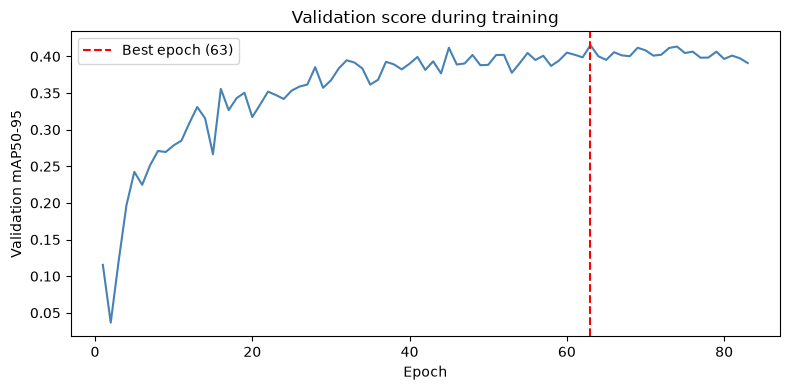

In [ ]:
run_record = ROOT/'reports/original_cleaned_v3/training'
log_df = pd.read_csv(run_record/'results.csv')
log_df.columns = log_df.columns.str.strip()

metric = 'metrics/mAP50-95(B)'
best_epoch = int(log_df.loc[log_df[metric].idxmax(), 'epoch'])
last_epoch = int(log_df['epoch'].iloc[-1])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(log_df['epoch'], log_df[metric], color='steelblue')
ax.axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch ({best_epoch})')
ax.set(title='Validation score during training', xlabel='Epoch',
       ylabel='Validation mAP50-95')
ax.legend(); plt.tight_layout(); plt.show()

print(f'Best epoch: {best_epoch} | training stopped at epoch: {last_epoch}')
print(log_df.loc[log_df['epoch'] == best_epoch,
      ['metrics/precision(B)', 'metrics/recall(B)',
       'metrics/mAP50(B)', 'metrics/mAP50-95(B)']].round(3).to_string(index=False))

### Test results
Shows the saved results from our original run on the test images, which the model never saw during training or when we chose the best checkpoint. This is the fair measure of how well it works on new images.

Running the test again is switched off by default (`RUN_TEST_EVALUATION = False`).

In [ ]:
RUN_TEST_EVALUATION = False
if RUN_TEST_EVALUATION:
    if best_model is None:
        raise RuntimeError('Set LOAD_TRAINED_MODEL=True and run the checkpoint-loading cell first.')
    if not DATA_YAML.is_file() or not DATA_ROOT.is_dir():
        raise RuntimeError('Restore and verify cleaned-v3 data in section 2 before evaluating.')
    test_metrics=best_model.val(data=str(DATA_YAML),split='test',imgsz=640,batch=16,
                                device=DEVICE,conf=0.001,iou=0.7,plots=True,
                                project=str(WORK/'evaluations'),name='fixed_checkpoint_test')
    print(f'Test precision: {test_metrics.box.mp:.4f}')
    print(f'Test recall: {test_metrics.box.mr:.4f}')
    print(f'Test mAP50: {test_metrics.box.map50:.4f}')
    print(f'Test mAP50-95: {test_metrics.box.map:.4f}')
else:
    print('New test evaluation skipped. The original output and saved verification remain available.')


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1167.1±522.9 MB/s, size: 59.1 KB)
val: Scanning /content/roadwatch_cleaned/test/labels... 369 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 369/369 1.8Kit/s 0.2s
val: New cache created: /content/roadwatch_cleaned/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.2s
                   all        369        873       0.79      0.679      0.771      0.484
Speed: 1.6ms preprocess, 10.5ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/drive/MyDrive/RoadWatch_cleaned_training/pothole_yolo11s_cleaned_v3/test_evaluation
Test precision: 0.7897
Test recall: 0.6795
Test mAP50: 0.7712
Test mAP50-95: 0.4841


### Read the results in plain language
- **Precision:** of the detections we made, how many matched annotated potholes?
- **Recall:** of the annotated potholes, how many did we find?
- **IoU:** how much the predicted box overlaps the answer box.
- **mAP50:** detection performance across confidence thresholds using IoU 0.50 to judge a match.
- **mAP50–95:** a stricter score averaged over IoU requirements from 0.50 to 0.95.

The recorded test scores are precision **78.97%**, recall **67.95%**, mAP50 **77.12%** and mAP50–95 **48.41%**. Do not call mAP50 “accuracy”. Missed potholes remain a concern, and stricter box placement reduces performance. These scores do not prove performance on Kenyan roads or a phone. Evaluator precision and recall need not equal performance at the app's confidence threshold of 0.25.


### The scores
The cell below compares two sets of test scores:

- **Original reported test:** the scores from the first run on a T4 GPU.
- **Separate reproduced CPU test:** the same model tested again on a CPU.

If the two rows are close, the reported scores are reliable. Small differences are normal. A large gap would mean we need to check the setup.

This only re-tests the same model. It does not show performance on Kenyan roads or on a phone.

In [ ]:
metrics=json.loads((ROOT/'reports/verification_2026-10-27/evaluation_metrics.json').read_text())
comparison=pd.DataFrame([
    {'Evidence':'Original reported test','Precision':78.97,'Recall':67.95,'mAP50':77.12,'mAP50–95':48.41},
    {'Evidence':'Separate reproduced CPU test','Precision':100*metrics['test']['precision'],
     'Recall':100*metrics['test']['recall'],'mAP50':100*metrics['test']['mAP50'],
     'mAP50–95':100*metrics['test']['mAP50_95']}])
display(comparison.round(3))
print('CPU verification is separate from the original T4 training and test run. No phone benchmark is claimed.')


CPU verification is separate from the original T4 training and test run. No phone benchmark is claimed.


,Evidence,Precision,Recall,mAP50,mAP50–95
0,Original reported test,78.970,67.950,77.120,48.410
1,Separate reproduced CPU test,78.966,67.946,77.123,48.406


### See predictions beside the answers
The images below come from the original test run. **Left** shows the annotated answers. **Right** shows what the model predicted. As you can see there are some annotated answers the model failed to predict owing to it not being all perfect. This is seen to especially really small potholes as a side effect of YOLO11 Small Object Detection Challenges.

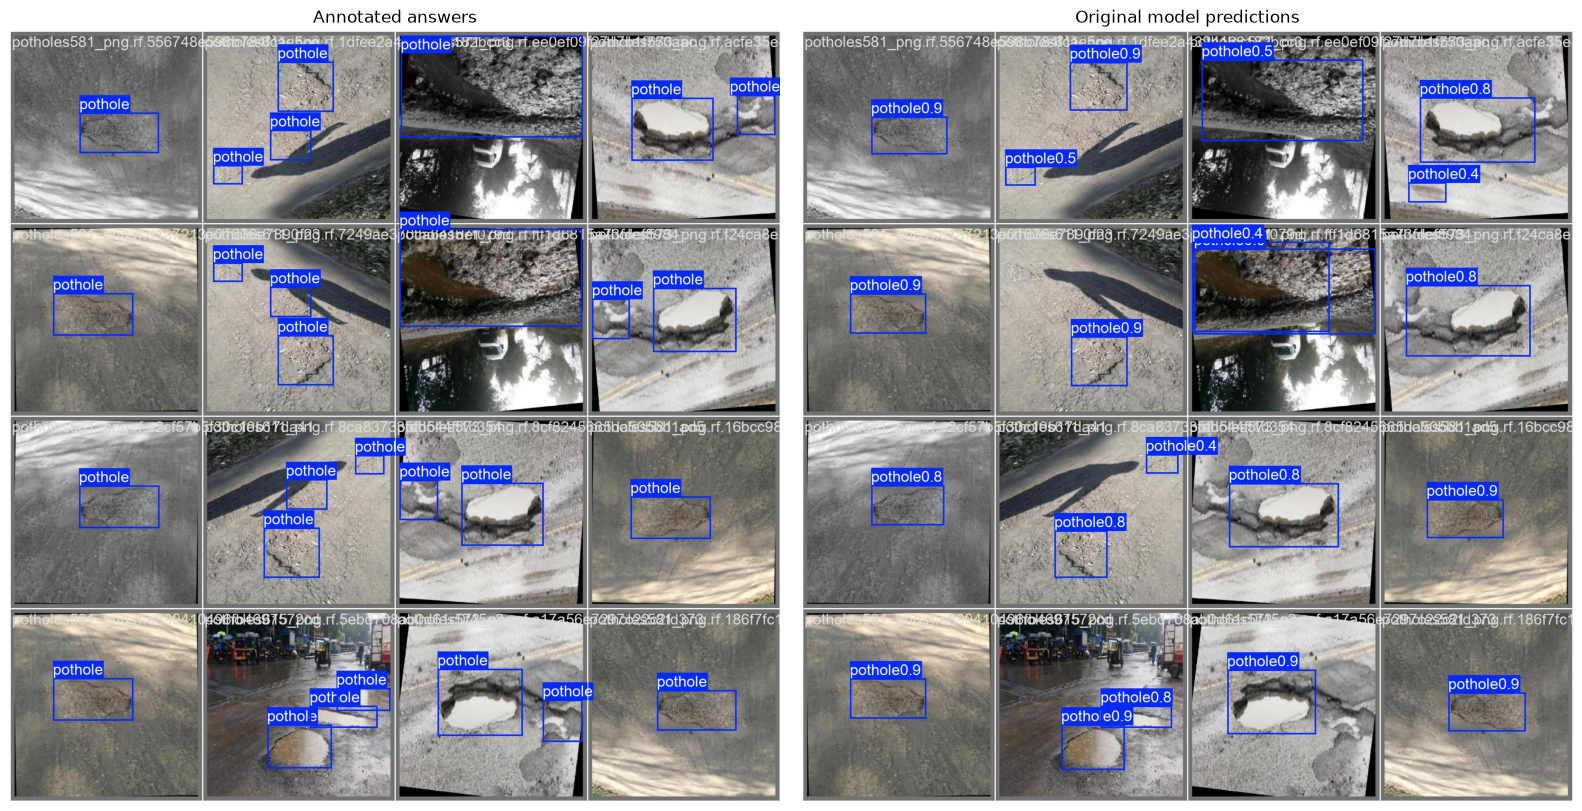

In [ ]:
folder=ROOT/'reports/original_cleaned_v3/test_evaluation'
fig,axes=plt.subplots(1,2,figsize=(16,8))
for ax,name,title in zip(axes,['val_batch0_labels.jpg','val_batch0_pred.jpg'],['Annotated answers','Original model predictions']):
    with Image.open(folder/name) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(title);ax.axis('off')
plt.tight_layout();plt.show()


### 4.8 Optional prediction on one new image
This runs inference only. Use an image you are allowed to use, record its source and do not claim it is independent unless that is known. It does not supply an accuracy score without reviewed ground-truth labels.


In [ ]:
RUN_DEMO = False
DEMO_IMAGE = Path('/content/road_demo.jpg')
if RUN_DEMO:
    if best_model is None:
        raise RuntimeError('Set LOAD_TRAINED_MODEL=True and run the checkpoint-loading cell first.')
    assert DEMO_IMAGE.is_file(), 'Upload your chosen image and set DEMO_IMAGE.'
    result=best_model.predict(source=str(DEMO_IMAGE),conf=0.25,imgsz=640,device=DEVICE,save=False)[0]
    plt.figure(figsize=(10,6));plt.imshow(result.plot()[...,::-1]);plt.axis('off');plt.show()
    print('Predicted boxes:',len(result.boxes),'— not independently verified potholes.')
else:
    print('Optional new-image prediction skipped.')


### 4.9 Optional checkpoint download
Optional COde for downloading the model, to your drive.


In [ ]:
DOWNLOAD_CHECKPOINT = False
if DOWNLOAD_CHECKPOINT:
    if not BEST_WEIGHTS.is_file():
        raise FileNotFoundError(f'Connect Drive and locate the existing checkpoint first: {BEST_WEIGHTS}')
    assert IN_COLAB, 'Use the local checkpoint file directly outside Colab.'
    from google.colab import files
    files.download(str(BEST_WEIGHTS))
else:
    print('Checkpoint remains at:',BEST_WEIGHTS)

## 5. What remains and future work


As for our remaining increments, we have:

- **Video input:** make the model read video, run detection on frames, and draw the boxes on the output.
- **Android integration:** export the model to a phone-friendly format and connect it to our Android application, so it can detect potholes from the phone camera.
- **Phone timing:** measure how fast detection runs on a real phone. No phone benchmark is claimed yet.
- **Further validation:** compare a second model under the same split conditions, test independent road sessions including pothole-free scenes, and inspect errors by predefined conditions. Use validation data for choices and keep independent testing separate.